# Final model for the app (Assignment 2)

DINOv2 ViT-S/14, fine-tuned on **all training data**, with one coin per denomination held out for testing.

| Subset | Content |
|---|---|
| Train | Part 1: `c0`, all 6 setups. Part 2: coins `c1`–`c6` of every denomination (30 coins) |
| Validation (choose the epoch) | Part 2: coin `c7` of every denomination (5 coins) |
| Test (never used for training or selection) | Part 2: coin `c8` of every denomination (5 coins) |

The test set is only 5 coins, so its accuracy is a rough estimate. It does not replace Experiment 2 of the paper (8 folds).
**This model was trained on 31 of the 41 coins (c0 and c1–c6), so its training coins overlap the paper's test coins; never use it for numbers in the paper.**

Outputs go to `results_a2/`: weights, training history, test metrics, embedding index of the training images (for the nearest-neighbour explanation), latency measurement.
The run is resumable: if it stops, run all cells again and it continues from the last finished epoch.

Pipeline check first: set `FAST = True` (a few images, 1 + 1 epochs), then switch back.

In [1]:
import os, sys, json, time
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")
sys.path.insert(0, os.path.abspath("."))
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

from coinlib.config import *
from coinlib.data import load_part1, load_part2
from coinlib.models import DEVICE, DinoClassifier
from coinlib import train as T

FAST = False
SEED = 42
VAL_COIN, TEST_COIN = "c7", "c8"
OUT = Path("results_a2_fast" if FAST else "results_a2"); OUT.mkdir(exist_ok=True)
LOG = OUT / "log.txt"

def log(msg):
    line = f"[{time.strftime('%H:%M:%S')}] {msg}"
    print(line, flush=True)
    with open(LOG, "a", encoding="utf-8") as f: f.write(line + "\n")
plt.rcParams["figure.dpi"] = 110
print("torch", torch.__version__, "| device:", DEVICE)

torch 2.14.1 | device: mps


## 1. Data and split

In [2]:
p1, p2 = load_part1(), load_part2()
tr = pd.concat([p1, p2[~p2.coin.isin([VAL_COIN, TEST_COIN])]], ignore_index=True)
va, te = p2[p2.coin == VAL_COIN].reset_index(drop=True), p2[p2.coin == TEST_COIN].reset_index(drop=True)
if FAST:
    tr, va, te = (d.groupby("label", group_keys=False).sample(6, random_state=0).reset_index(drop=True) for d in (tr, va, te))
assert not set(tr.path) & set(va.path) and not set(tr.path) & set(te.path) and not set(va.path) & set(te.path)
print(f"train {len(tr)} | val {len(va)} | test {len(te)}")
print(pd.crosstab(tr.cls.reindex(tr.index), tr.part).reindex(CLASSES).to_string())
print("test images per class:", te.cls.value_counts().reindex(CLASSES).tolist())

train 2295 | val 200 | test 199
part        P1   P2
cls                
5_tenge    220  232
10_tenge   223  239
20_tenge   217  240
50_tenge   214  240
100_tenge  235  235
test images per class: [40, 40, 40, 39, 40]


## 2. Training (resumable, checkpoint after every epoch)

In [3]:
cfg = dict(head_epochs=1, ft_epochs=1) if FAST else {}
log(f"START final DINOv2 | train {len(tr)} | val {len(va)} | test {len(te)} | device {DEVICE}")
t0 = time.time()
model, hist = T.train_dino(tr, va, SEED, OUT / "ckpt.pt", log=log, cfg=cfg)
train_min = (time.time() - t0) / 60
torch.save(model.state_dict(), OUT / "final_dinov2.pt")
json.dump(hist, open(OUT / "history.json", "w"))
log(f"DONE training: {len(hist['val_loss'])} epochs, {train_min:.1f} min in this session")

[22:18:50] START final DINOv2 | train 2295 | val 200 | test 199 | device mps


/Users/sabirakurbankhozha/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/Users/sabirakurbankhozha/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/Users/sabirakurbankhozha/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


[22:19:40]     epoch  1 | train loss 1.140 acc 0.592 | val loss 1.199 acc 0.550 | 48s


[22:20:10]     epoch  2 | train loss 0.762 acc 0.792 | val loss 1.074 acc 0.615 | 29s


[22:20:40]     epoch  3 | train loss 0.653 acc 0.840 | val loss 1.070 acc 0.635 | 29s


[22:21:10]     epoch  4 | train loss 0.599 acc 0.864 | val loss 1.133 acc 0.595 | 30s


... (6 outputs left out)

[22:33:06]     epoch 11 | train loss 0.269 acc 0.991 | val loss 1.031 acc 0.750 | 96s


[22:34:44]     epoch 12 | train loss 0.256 acc 0.995 | val loss 1.071 acc 0.735 | 97s


[22:36:23]     epoch 13 | train loss 0.247 acc 0.998 | val loss 1.027 acc 0.725 | 98s


[22:36:24] DONE training: 13 epochs, 17.6 min in this session


## 3. Held-out test (coin c8 of every denomination)

linear head: accuracy 0.834 | macro F1 0.830
              precision    recall  f1-score   support

           5       0.77      0.50      0.61        40
          10       0.64      0.88      0.74        40
          20       0.85      1.00      0.92        40
          50       1.00      0.79      0.89        39
         100       1.00      1.00      1.00        40

    accuracy                           0.83       199
   macro avg       0.85      0.83      0.83       199
weighted avg       0.85      0.83      0.83       199



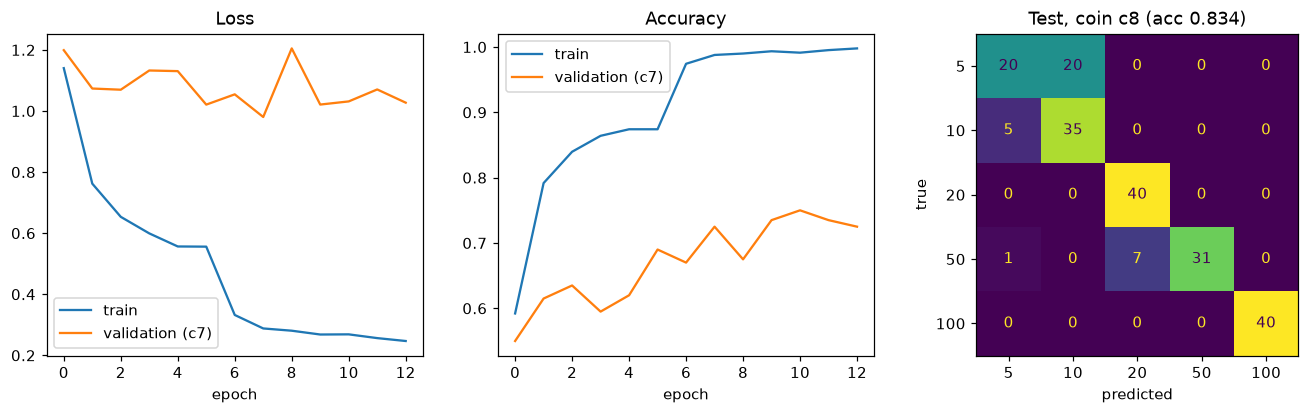

In [4]:
prob, emb_te = T.predict(model, te)
pred = prob.argmax(1); y = te.label.to_numpy()
acc, f1 = accuracy_score(y, pred), f1_score(y, pred, average="macro", labels=range(5), zero_division=0)
print(f"linear head: accuracy {acc:.3f} | macro F1 {f1:.3f}")
print(classification_report(y, pred, labels=range(5), target_names=SHORT, zero_division=0))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (k, t) in zip(ax[:2], [("loss", "Loss"), ("acc", "Accuracy")]):
    a.plot(hist["train_" + k], label="train"); a.plot(hist["val_" + k], label="validation (c7)"); a.set_title(t); a.set_xlabel("epoch"); a.legend()
ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=range(5)), display_labels=SHORT).plot(ax=ax[2], colorbar=False)
ax[2].set_title(f"Test, coin c8 (acc {acc:.3f})"); ax[2].set_xlabel("predicted"); ax[2].set_ylabel("true")
plt.savefig(OUT / "final_curves_confusion.png", bbox_inches="tight"); plt.show()

In [5]:
# Per side and per coin-denomination, plus the most confident errors
te_ = te.assign(pred=pred, conf=prob.max(1), ok=pred == y)
print(te_.groupby("side").ok.mean().round(3).to_dict())
print(te_.groupby("cls").ok.mean().reindex(CLASSES).round(3).to_dict())
print(te_[~te_.ok].sort_values("conf", ascending=False)[["cls", "side", "pred", "conf"]].head(10).assign(pred=lambda d: d.pred.map(dict(enumerate(SHORT)))).to_string())

{'obverse': 0.99, 'reverse': 0.68}
{'5_tenge': 0.5, '10_tenge': 0.875, '20_tenge': 1.0, '50_tenge': 0.795, '100_tenge': 1.0}
          cls     side pred      conf
153  50_tenge  reverse   20  0.939838
24    5_tenge  reverse   10  0.925142
32    5_tenge  reverse   10  0.916455
25    5_tenge  reverse   10  0.881924
34    5_tenge  reverse   10  0.869941
28    5_tenge  reverse   10  0.862842
35    5_tenge  reverse   10  0.849124
31    5_tenge  reverse   10  0.848340
152  50_tenge  reverse   20  0.836385
20    5_tenge  reverse   10  0.827407


## 4. Embedding index (for the nearest-neighbour explanation) and kNN on embeddings

The index holds the **training** images only, embedded without augmentation by the final fine-tuned model. kNN with cosine similarity is compared with the linear head on the same held-out coins (finding 8 of the paper notes).

In [6]:
_, emb_tr = T.predict(model, tr)
root = str(Path(".").resolve()) + "/"
rel = [p.replace(root, "") for p in tr.path]
np.savez_compressed(OUT / "index.npz", emb=emb_tr.astype("float32"), paths=np.array(rel), label=tr.label.to_numpy(),
                    coin=tr.coin.to_numpy(), side=tr.side.to_numpy(), part=tr.part.to_numpy())

def knn_predict(q, emb, labels, k=5):
    sims = q @ emb.T                                        # embeddings are L2-normalised: cosine similarity
    idx = np.argsort(-sims, 1)[:, :k]
    votes = np.zeros((len(q), 5))
    for r in range(len(q)):
        for j in idx[r]: votes[r, labels[j]] += sims[r, j]
    return votes.argmax(1), votes / votes.sum(1, keepdims=True)

res = {"head": dict(acc=acc, f1=f1)}
for k in (1, 5, 10):
    kp, _ = knn_predict(emb_te, emb_tr, tr.label.to_numpy(), k)
    res[f"knn{k}"] = dict(acc=accuracy_score(y, kp), f1=f1_score(y, kp, average="macro", labels=range(5), zero_division=0))
print(pd.DataFrame(res).T.round(3))

         acc     f1
head   0.834  0.830
knn1   0.789  0.786
knn5   0.829  0.828
knn10  0.839  0.838


## 5. Latency on this machine (single image, model only)

In [7]:
x = torch.randn(1, 3, 224, 224, device=DEVICE); model.eval()
sync = torch.mps.synchronize if DEVICE == "mps" else (torch.cuda.synchronize if DEVICE == "cuda" else (lambda: None))
with torch.no_grad():
    for _ in range(3): model(x)
    sync(); ts = []
    for _ in range(20):
        t = time.perf_counter(); model(x); sync(); ts.append((time.perf_counter() - t) * 1000)
lat = dict(device=DEVICE, ms_mean=float(np.mean(ts)), ms_std=float(np.std(ts)))
print(lat)

{'device': 'mps', 'ms_mean': 9.499800100456923, 'ms_std': 0.17757091165473765}


In [8]:
meta = dict(seed=SEED, val_coin=VAL_COIN, test_coin=TEST_COIN, n_train=len(tr), n_val=len(va), n_test=len(te),
            epochs=len(hist["val_loss"]), best_val_loss=min(hist["val_loss"]), head=res["head"], knn=res, latency=lat,
            classes=CLASSES, note="Trained on 31 of 41 coins (c0, c1-c6); do not use for paper numbers.")
json.dump(meta, open(OUT / "final_metrics.json", "w"), indent=1)
print(json.dumps(meta, indent=1))

{
 "seed": 42,
 "val_coin": "c7",
 "test_coin": "c8",
 "n_train": 2295,
 "n_val": 200,
 "n_test": 199,
 "epochs": 13,
 "best_val_loss": 0.9803521585464477,
 "head": {
  "acc": 0.8341708542713567,
  "f1": 0.8296314453846214
 },
 "knn": {
  "head": {
   "acc": 0.8341708542713567,
   "f1": 0.8296314453846214
  },
  "knn1": {
   "acc": 0.7889447236180904,
   "f1": 0.7864743833017078
  },
  "knn5": {
   "acc": 0.8291457286432161,
   "f1": 0.8276871947186585
  },
  "knn10": {
   "acc": 0.8391959798994975,
   "f1": 0.838282220607802
  }
 },
 "latency": {
  "device": "mps",
  "ms_mean": 9.499800100456923,
  "ms_std": 0.17757091165473765
 },
 "classes": [
  "5_tenge",
  "10_tenge",
  "20_tenge",
  "50_tenge",
  "100_tenge"
 ],
 "note": "Trained on 31 of 41 coins (c0, c1-c6); do not use for paper numbers."
}
